0. 引包

In [443]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LogisticRegression as LR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB,BernoulliNB,MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier

import warnings
warnings.filterwarnings('ignore')

In [444]:
font={'family':'Arial Unicode MS',
     'weight':'normal',
     'size':14}
plt.rc('font',**font)
plt.rc('axes',unicode_minus=False)

1. 准备数据

In [445]:
data=pd.read_excel('./2.数据/个人消费贷是否违约.xlsx')
data

,信用额度,性别,教育,婚姻状况,年龄,10月还款,9月还款,8月还款,7月还款,6月还款,...,7月的账单金额,6月的账单金额,5月的账单金额,10月支付金额,9月支付金额,8月支付金额,7月支付金额,6月支付金额,5月支付金额,是否违约
0,20000,女,研究生,已婚,24,还款延迟二个月,还款延迟二个月,按时还款,按时还款,提前还款,...,0,0,0,0,689,0,0,0,0,是
1,120000,女,研究生,未婚,26,按时还款,还款延迟二个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,...,3272,3455,3261,0,1000,1000,1000,0,2000,是
2,90000,女,研究生,未婚,34,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,否
3,50000,女,研究生,已婚,37,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,否
4,50000,男,研究生,已婚,57,按时还款,还款延迟不到一个月,按时还款,还款延迟不到一个月,还款延迟不到一个月,...,20940,19146,19131,2000,36681,10000,9000,689,679,否
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,男,高中,已婚,39,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,否
29996,150000,男,高中,未婚,43,按时还款,按时还款,按时还款,按时还款,还款延迟不到一个月,...,8979,5190,0,1837,3526,8998,129,0,0,否
29997,30000,男,研究生,未婚,37,还款延迟四个月,还款延迟三个月,还款延迟二个月,按时还款,还款延迟不到一个月,...,20878,20582,19357,0,0,22000,4200,2000,3100,是
29998,80000,男,高中,已婚,41,还款延迟一个月,按时还款,还款延迟不到一个月,还款延迟不到一个月,还款延迟不到一个月,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,是


In [446]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   信用额度      30000 non-null  int64 
 1   性别        30000 non-null  object
 2   教育        30000 non-null  object
 3   婚姻状况      30000 non-null  object
 4   年龄        30000 non-null  int64 
 5   10月还款     30000 non-null  object
 6   9月还款      30000 non-null  object
 7   8月还款      30000 non-null  object
 8   7月还款      30000 non-null  object
 9   6月还款      30000 non-null  object
 10  5月还款      30000 non-null  object
 11  10月的账单金额  30000 non-null  int64 
 12  9月的账单金额   30000 non-null  int64 
 13  8月的账单金额   30000 non-null  int64 
 14  7月的账单金额   30000 non-null  int64 
 15  6月的账单金额   30000 non-null  int64 
 16  5月的账单金额   30000 non-null  int64 
 17  10月支付金额   30000 non-null  int64 
 18  9月支付金额    30000 non-null  int64 
 19  8月支付金额    30000 non-null  int64 
 20  7月支付金额    30000 non-null  int64 
 21  6月支付金额    30

2. 数据清洗+特征工程
- 数据清洗
    - 修正噪声数据：5-10月均按时还款，但显示违约
- 特征工程
    - 标签数据：'是否违约'——二值化
    - 文本字段:01编码+数值化
        - 用户信息：'性别', '教育', '婚姻状况'
    - 文本字段：用户还款行为量化：各状态分类汇总col；违约总次数col/无违约总次数col；违约总次数占比；  
        - 用户行为：'10月还款', '9月还款', '8月还款', '7月还款','6月还款', '5月还款'
    - 账单金额
        - 用户行为：'10月的账单金额', '9月的账单金额', '8月的账单金额', '7月的账单金额', '6月的账单金额', '5月的账单金额'
            - 借钱/还钱项目分位点分别计算后整体分段
    - 数值字段：分段化
        - 用户信息：'信用额度', '年龄'
        - 用户行为：5-10月支付金额：['10月支付金额', '9月支付金额', '8月支付金额', '7月支付金额', '6月支付金额', '5月支付金额']
            - 平均分位点

数据清洗：修正噪声数据

In [447]:
def get_zaosheng(a,b,c,d,e,f,y):
    if y=='否':
        return 0
    month_lst=[a,b,c,d,e,f]
    for i in [a,b,c,d,e,f]:
        if '延迟' in str(i):
            return 0
    return 1

In [448]:
data['是否噪声']=data.apply(lambda x:get_zaosheng(x['10月还款'],
                                 x['9月还款'],
                                 x['8月还款'],
                                 x['7月还款'],
                                 x['6月还款'],
                                 x['5月还款'],
                                 x['是否违约']),axis=1)

In [449]:
#噪声数据占比
len(data[data['是否噪声']==1])/len(data)

0.0246

In [450]:
#修正噪声数据代码
#data['是否违约'][data['是否噪声']==1]='否'

In [451]:
#删除噪声数据代码
zaosheng_data=data[data['是否噪声']==1]
data.drop(index=zaosheng_data.index,inplace=True)

In [452]:
#删除辅助查找噪声数据列
data.drop(columns='是否噪声',inplace=True)

- 特征工程
    - (1) 标签数据二值化

In [454]:
data['是否违约']=data['是否违约'].apply(lambda x:1 if x=='是' else 0)

- 特征工程
    - (2) 用户信息:['性别', '教育', '婚姻状况']
        - 01编码+数值化

In [455]:
data_info=['性别', '教育', '婚姻状况']

In [456]:
#01编码
for col in data_info:
    uniq=data[col].unique()
    for i in uniq:
        data[col+'_'+i]=data[col].apply(lambda x:1 if x==i else 0)

In [457]:
#数值化
for col in data_info:
    uniq=list(data[col].unique())
    data[col]=data[col].apply(lambda x:uniq.index(x))

- 特征工程
    - (3) 行为信息：['10月还款', '9月还款', '8月还款', '7月还款','6月还款', '5月还款']
        - a.所有月不同状态分类汇总
        - b.总违约次数col；总不违约次数col；违约次数占比col
        - c.延迟还款不同时长分段统计：

In [458]:
#找到所有状态的可能
huankuan_col=['10月还款', '9月还款', '8月还款', '7月还款','6月还款', '5月还款']
zhuangtai=[]
for col in huankuan_col:
    uniq_lst=list(data[col].unique())
    zhuangtai.extend(uniq_lst)
zhuangtai=list(set(zhuangtai))

In [459]:
zhuangtai

['还款延迟不到一个月',
 '还款延迟六个月',
 '还款延迟四个月',
 '提前还款',
 '还款延迟七个月',
 '还款延迟五个月',
 '还款延迟一个月',
 '还款延迟二个月',
 '还款延迟三个月',
 '按时还款',
 '还款延迟八个月']

In [460]:
#状态行为自定义排序
zhuangtai=['提前还款',
           '按时还款',
           '还款延迟不到一个月',
           '还款延迟一个月',
           '还款延迟二个月',
           '还款延迟三个月',
           '还款延迟四个月',
           '还款延迟五个月',
           '还款延迟六个月',
           '还款延迟七个月',
           '还款延迟八个月']

In [461]:
#得到5-10月还款状态合并文本，便于统计次数
data['还款_strsum']=data['10月还款']+','+data['9月还款']+','+data['8月还款']+','+data['7月还款']+','+data['6月还款']+','+data['5月还款']

In [462]:
#统计1:每个用户5-10月不同还款状态分类汇总
for zt in zhuangtai:
    data[zt+'_次数']=data['还款_strsum'].apply(lambda x:x.count(zt))

In [463]:
#统计2:延迟还款次数、没有延迟次数、延迟还款次数占比
data['延迟还款次数']=data[['还款延迟不到一个月_次数',
       '还款延迟二个月_次数', '还款延迟三个月_次数', '还款延迟四个月_次数', '还款延迟五个月_次数', '还款延迟六个月_次数',
       '还款延迟七个月_次数', '还款延迟八个月_次数']].sum(axis=1)
data['按时/提前还款次数']=6-data['延迟还款次数']
data['延迟次数占比']=data['延迟还款次数']/6

统计3:延迟还款状态分段统计
- 分类1:不到1个月-1个月，延迟2-3月，2-4月，2-5月，2-6月，2-7月，2-8月
- 分类2:不到1个月-2个月，延迟3-4月，3-5月，3-6月，3-8月
- 分类3:不到1个月-3个月，延迟4-5月，4-6月，4-7月，4-8月
- 分类4:不到1个月-4个月，延迟5-6月，5-7月，5-8月
- 分类5:不到1个月-5个月，延迟6-7月，6-8月
- 分类6:不到1个月-6个月，延迟7-8月
- 分类7:不到1个月-7个月

In [464]:
#分类1
data['延迟_1']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数']].sum(axis=1)
data['延迟_2-3']=data[['还款延迟二个月_次数','还款延迟三个月_次数']].sum(axis=1)
data['延迟_2-4']=data[['还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数']].sum(axis=1)
data['延迟_2-5']=data[['还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数']].sum(axis=1)
data['延迟_2-6']=data[['还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数']].sum(axis=1)
data['延迟_2-7']=data[['还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)
data['延迟_2-8']=data[['还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [465]:
#分类2
data['延迟_2']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数']].sum(axis=1)
data['延迟_3-4']=data[['还款延迟三个月_次数','还款延迟四个月_次数']].sum(axis=1)
data['延迟_3-5']=data[['还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数']].sum(axis=1)
data['延迟_3-6']=data[['还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数']].sum(axis=1)
data['延迟_3-7']=data[['还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)
data['延迟_3-8']=data[['还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [466]:
#分类3
data['延迟_3']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数','还款延迟三个月_次数']].sum(axis=1)
data['延迟_4-5']=data[['还款延迟四个月_次数','还款延迟五个月_次数']].sum(axis=1)
data['延迟_4-6']=data[['还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数']].sum(axis=1)
data['延迟_4-7']=data[['还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)
data['延迟_4-8']=data[['还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [467]:
#分类4
data['延迟_4']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数']].sum(axis=1)
data['延迟_5-6']=data[['还款延迟五个月_次数','还款延迟六个月_次数']].sum(axis=1)
data['延迟_5-7']=data[['还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)
data['延迟_5-8']=data[['还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [468]:
#分类5
data['延迟_5']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数']].sum(axis=1)
data['延迟_6-7']=data[['还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)
data['延迟_6-8']=data[['还款延迟六个月_次数','还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [469]:
#分类6
data['延迟_6']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数']].sum(axis=1)
data['延迟_7-8']=data[['还款延迟七个月_次数','还款延迟八个月_次数']].sum(axis=1)

In [470]:
#分类7
data['延迟_7']=data[['还款延迟不到一个月_次数','还款延迟一个月_次数','还款延迟二个月_次数','还款延迟三个月_次数','还款延迟四个月_次数','还款延迟五个月_次数','还款延迟六个月_次数','还款延迟七个月_次数']].sum(axis=1)

统计4:5-10月还款原列数值化

In [471]:
huankuan_col

['10月还款', '9月还款', '8月还款', '7月还款', '6月还款', '5月还款']

In [472]:
zhuangtai

['提前还款',
 '按时还款',
 '还款延迟不到一个月',
 '还款延迟一个月',
 '还款延迟二个月',
 '还款延迟三个月',
 '还款延迟四个月',
 '还款延迟五个月',
 '还款延迟六个月',
 '还款延迟七个月',
 '还款延迟八个月']

In [473]:
for col in huankuan_col:
    data[col]=data[col].apply(lambda x:zhuangtai.index(x))

In [474]:
#删除辅助列：还款_strsum
data.drop(columns='还款_strsum',inplace=True)

- 特征工程
    - (4) 数据信息：账单金额、支付金额、'信用额度', '年龄'——分段化
        - a.账单金额：['10月的账单金额', '9月的账单金额', '8月的账单金额', '7月的账单金额', '6月的账单金额', '5月的账单金额']
            - 负数、正数分段标准分开计算
        - b.支付金额：['10月支付金额', '9月支付金额', '8月支付金额', '7月支付金额', '6月支付金额', '5月支付金额']
            - 统一分段化标准
        - c.'信用额度', '年龄'
            - 正常分段化

- 账单金额

In [475]:
zhangdan_col=['10月的账单金额', '9月的账单金额', '8月的账单金额', '7月的账单金额', '6月的账单金额', '5月的账单金额']

In [476]:
#各月账单分布情况(describe显示负数数据不足10%)
data[zhangdan_col].describe(percentiles=np.linspace(0.1,0.9,9))

,10月的账单金额,9月的账单金额,8月的账单金额,7月的账单金额,6月的账单金额,5月的账单金额
count,29262.000000,29262.000000,2.926200e+04,29262.000000,29262.000000,29262.000000
mean,52395.132356,50327.713758,4.811053e+04,44270.324653,41253.394197,39770.382100
std,74100.992370,71629.102702,6.981803e+04,64768.237386,61234.242939,59950.479628
min,-165580.000000,-69777.000000,-1.572640e+05,-170000.000000,-81334.000000,-209051.000000
10%,316.000000,76.100000,0.000000e+00,0.000000,0.000000,0.000000
20%,2280.000000,1795.000000,1.479200e+03,1217.400000,918.200000,604.200000
30%,6892.000000,6378.000000,6.152000e+03,5543.300000,4450.600000,3274.000000
40%,14702.800000,14192.800000,1.352340e+04,12440.800000,10575.400000,9538.600000
50%,24018.000000,22906.000000,2.108500e+04,19592.500000,18726.000000,17899.000000
60%,39002.400000,36628.600000,3.301860e+04,29263.400000,27668.200000,26584.800000


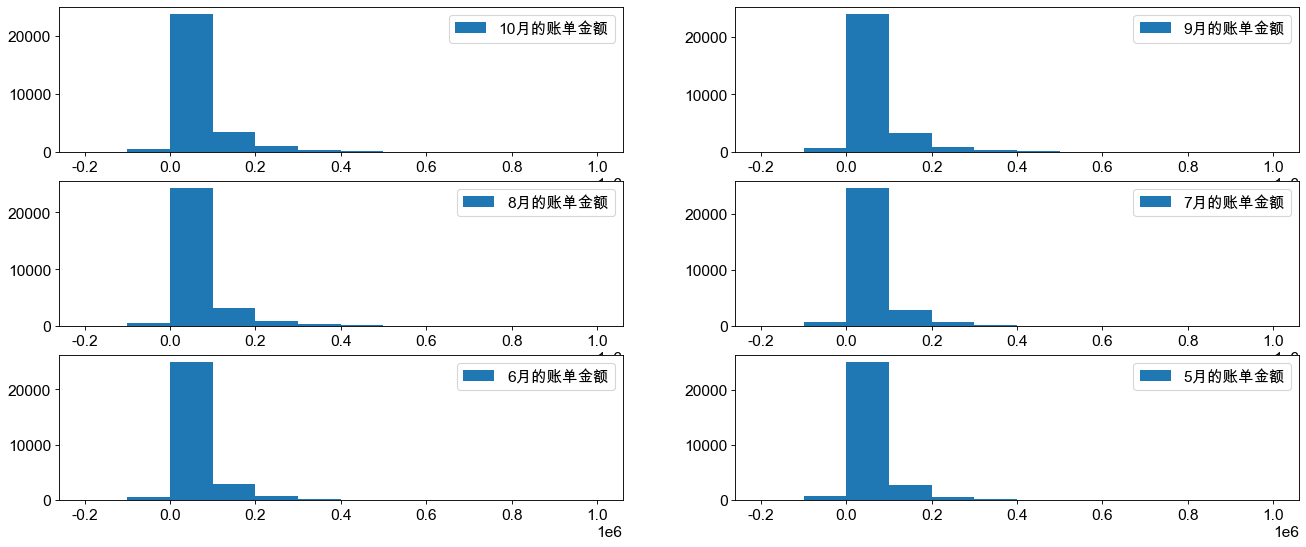

In [478]:
#直方图显示
plt.figure(figsize=(20,8),dpi=80)

plt.subplot(321)
plt.hist(data['10月的账单金额'],label='10月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.subplot(322)
plt.hist(data['9月的账单金额'],label='9月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.subplot(323)
plt.hist(data['8月的账单金额'],label='8月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.subplot(324)
plt.hist(data['7月的账单金额'],label='7月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.subplot(325)
plt.hist(data['6月的账单金额'],label='6月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.subplot(326)
plt.hist(data['5月的账单金额'],label='5月的账单金额',bins=12,range=(-200000,1000000))
plt.legend()

plt.show()

- 账单金额数据分析结果：
    - 负数占比极少，不足10%
    - 正数呈现拖尾状态，前少后多
    - 各月份账单金额分布大致相同

In [479]:
#每个月账单金额为负的四分位点及其均值
data_zd0jian=pd.DataFrame(index=['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max'])
for col in zhangdan_col:
    data_zd0jian[col]=data[col][data[col]<0].describe()
data_zd0jian['5-10月账单金额平均']=data_zd0jian.mean(axis=1)
data_zd0jian

,10月的账单金额,9月的账单金额,8月的账单金额,7月的账单金额,6月的账单金额,5月的账单金额,5-10月账单金额平均
count,560.000000,619.000000,607.000000,628.000000,611.000000,652.000000,612.833333
mean,-1203.923214,-1288.117932,-1444.833608,-1615.853503,-1697.472995,-2606.038344,-1642.706599
std,9672.520177,5116.106274,7254.696242,8466.851427,6160.125182,12328.133878,8166.405530
min,-165580.000000,-69777.000000,-157264.000000,-170000.000000,-81334.000000,-209051.000000,-142167.666667
25%,-470.250000,-678.500000,-815.000000,-916.000000,-1000.000000,-1147.000000,-837.791667
50%,-93.500000,-131.000000,-152.000000,-162.000000,-200.000000,-202.500000,-156.833333
75%,-11.750000,-15.000000,-15.000000,-18.000000,-18.000000,-20.000000,-16.291667
max,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000


In [480]:
#每个月账单金额为正的十位点及其均值
data_zd0jia=pd.DataFrame(index=['count', 'mean', 'std', 'min', '10%', '20%', '30%', '40%', '50%', '60%',
                                '70%', '80%', '90%', 'max'])
for col in zhangdan_col:
    data_zd0jia[col]=data[col][data[col]>0].describe(percentiles=np.linspace(0.1,0.9,9))
data_zd0jia['5-10月账单金额平均']=data_zd0jia.mean(axis=1)
data_zd0jia

,10月的账单金额,9月的账单金额,8月的账单金额,7月的账单金额,6月的账单金额,5月的账单金额,5-10月账单金额平均
count,26838.000000,26371.000000,2.602000e+04,25714.000000,25422.000000,24869.000000,2.587233e+04
mean,57152.565765,55875.276061,5.413863e+04,50418.176713,47525.528165,46863.969520,5.199569e+04
std,75575.870488,73355.734106,7.178211e+04,66784.918853,63366.210670,62366.973721,6.887197e+04
min,1.000000,3.000000,1.000000e+00,2.000000,1.000000,1.000000,1.500000e+00
10%,1501.400000,1491.000000,1.473000e+03,1468.000000,1279.100000,1170.000000,1.397083e+03
20%,5000.000000,5142.000000,5.412600e+03,5378.000000,4777.400000,4379.800000,5.014967e+03
30%,10711.100000,11158.000000,1.145620e+04,11008.800000,10076.600000,9780.000000,1.069845e+04
40%,18611.200000,18816.000000,1.883280e+04,18271.800000,17533.400000,17180.000000,1.820753e+04
50%,28787.000000,28675.000000,2.790500e+04,25764.000000,23764.000000,23467.000000,2.639367e+04
60%,45417.800000,44434.000000,4.192040e+04,36559.600000,32282.000000,31971.400000,3.876420e+04


In [481]:
#合并分位点,共13个分位点，可以划分成14分段
fenweidian_fu=data_zd0jian['5-10月账单金额平均'][[ '25%', '50%', '75%' ,'max']]
fenweidian_zheng=data_zd0jia['5-10月账单金额平均'][[ '10%', '20%', '30%', '40%', '50%', '60%',
       '70%', '80%', '90%']]
zhangdan_fenweidian=list(pd.concat((fenweidian_fu,fenweidian_zheng)).values)
zhangdan_fenweidian

[-837.7916666666666,
 -156.83333333333334,
 -16.291666666666668,
 -1.0,
 1397.0833333333333,
 5014.966666666667,
 10698.450000000003,
 18207.533333333336,
 26393.666666666668,
 38764.2,
 54841.34999999997,
 84180.56666666671,
 138316.9]

In [482]:
#自定义14分段函数
def get_cut14(x,cut14_1,cut14_2,cut14_3,cut14_4,cut14_5,cut14_6,cut14_7,
               cut14_8,cut14_9,cut14_10,cut14_11,cut14_12,cut14_13):
    if x<cut14_1:
        return 1
    elif x<cut14_2:
        return 2
    elif x<cut14_3:
        return 3
    elif x<cut14_4:
        return 4
    elif x<cut14_5:
        return 5
    elif x<cut14_6:
        return 6
    elif x<cut14_7:
        return 7
    elif x<cut14_8:
        return 8
    elif x<cut14_9:
        return 9
    elif x<cut14_10:
        return 10
    elif x<cut14_11:
        return 11
    elif x<cut14_12:
        return 12
    elif x<cut14_13:
        return 13
    else:
        return 14

In [483]:
cut14_1,cut14_2,cut14_3,cut14_4,cut14_5,cut14_6,cut14_7,cut14_8,cut14_9,cut14_10,cut14_11,cut14_12,cut14_13=zhangdan_fenweidian

In [484]:
#5-10月账单金额14分段
for col in zhangdan_col:
    data[col]=data[col].apply(lambda x:get_cut14(x,cut14_1,cut14_2,cut14_3,cut14_4,cut14_5,cut14_6,cut14_7,
                                                 cut14_8,cut14_9,cut14_10,cut14_11,cut14_12,cut14_13))

- 支付金额字段+信息额度+年龄分段化
    - 支付金额分段值：求平均
    - 合并支付金额平均分位值与信息额度、年龄正常计算分位值

In [485]:
zhifu_col=['10月支付金额', '9月支付金额', '8月支付金额', '7月支付金额', '6月支付金额', '5月支付金额']

In [486]:
zhifu_des4=data[zhifu_col].describe()
zhifu_des4['5-10月支付均值']=zhifu_des4.mean(axis=1)
zhifu_des4

,10月支付金额,9月支付金额,8月支付金额,7月支付金额,6月支付金额,5月支付金额,5-10月支付均值
count,29262.000000,2.926200e+04,29262.000000,29262.000000,29262.000000,29262.000000,29262.000000
mean,5740.145684,6.002374e+03,5288.095380,4882.488415,4834.252033,5251.711742,5333.177807
std,16710.632704,2.328212e+04,17748.222172,15788.783636,15333.672492,17777.345147,17773.462002
min,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1000.000000,1.000000e+03,451.250000,316.000000,300.000000,174.000000,540.208333
50%,2178.000000,2.043000e+03,1894.000000,1507.000000,1546.000000,1500.000000,1778.000000
75%,5030.750000,5.000000e+03,4616.750000,4100.000000,4100.000000,4019.000000,4477.750000
max,873552.000000,1.684259e+06,896040.000000,621000.000000,426529.000000,528666.000000,838341.000000


In [487]:
zhifu_des10=data_zhifu.describe(percentiles=np.linspace(0.1,0.9,9))
zhifu_des10['5-10月支付均值']=zhifu_des10.mean(axis=1)
zhifu_des10

,10月支付金额,9月支付金额,8月支付金额,7月支付金额,6月支付金额,5月支付金额,5-10月支付均值
count,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,5275.232094
std,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,17655.507237
min,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
10%,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
20%,316.000000,2.688000e+02,2.80000,0.000000,0.000000,0.000000,97.933333
30%,1263.700000,1.165000e+03,780.00000,500.000000,500.000000,426.000000,772.450000
40%,1724.000000,1.600000e+03,1206.00000,1000.000000,1000.000000,1000.000000,1255.000000
50%,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,1734.833333
60%,3000.000000,3.000000e+03,2500.00000,2100.000000,2123.400000,2100.000000,2470.566667


In [488]:
xinxi_des4=data[['信用额度', '年龄']].describe()
xinxi_des4

,信用额度,年龄
count,29262.000000,29262.000000
mean,166185.827353,35.434488
std,129669.090894,9.214066
min,10000.000000,21.000000
25%,50000.000000,28.000000
50%,140000.000000,34.000000
75%,240000.000000,41.000000
max,1000000.000000,79.000000


In [489]:
xinxi_des10=data[['信用额度', '年龄']].describe(np.linspace(0.1,0.9,9))
xinxi_des10

,信用额度,年龄
count,29262.000000,29262.000000
mean,166185.827353,35.434488
std,129669.090894,9.214066
min,10000.000000,21.000000
10%,30000.000000,25.000000
20%,50000.000000,27.000000
30%,70000.000000,29.000000
40%,100000.000000,31.000000
50%,140000.000000,34.000000
60%,180000.000000,37.000000


- 合并分段值

In [490]:
cut_des4=pd.concat((zhifu_des4['5-10月支付均值'],xinxi_des4),axis=1)
cut_des4

,5-10月支付均值,信用额度,年龄
count,29262.000000,29262.000000,29262.000000
mean,5333.177807,166185.827353,35.434488
std,17773.462002,129669.090894,9.214066
min,0.000000,10000.000000,21.000000
25%,540.208333,50000.000000,28.000000
50%,1778.000000,140000.000000,34.000000
75%,4477.750000,240000.000000,41.000000
max,838341.000000,1000000.000000,79.000000


In [491]:
cut_des10=pd.concat((zhifu_des10['5-10月支付均值'],xinxi_des10),axis=1)
cut_des10

,5-10月支付均值,信用额度,年龄
count,30000.000000,29262.000000,29262.000000
mean,5275.232094,166185.827353,35.434488
std,17655.507237,129669.090894,9.214066
min,0.000000,10000.000000,21.000000
10%,0.000000,30000.000000,25.000000
20%,97.933333,50000.000000,27.000000
30%,772.450000,70000.000000,29.000000
40%,1255.000000,100000.000000,31.000000
50%,1734.833333,140000.000000,34.000000
60%,2470.566667,180000.000000,37.000000


- 自定义分段化函数

In [492]:
def get_cut4(x,cut4_1,cut4_2,cut4_3):
    if x<cut4_1:
        return 1
    elif x<cut4_2:
        return 2
    elif x<cut4_3:
        return 3
    else:
        return 4

In [493]:
def get_cut10(x,cut10_1,cut10_2,cut10_3,cut10_4,cut10_5,cut10_6,cut10_7,cut10_8,cut10_9):
    if x<cut10_1:
        return 1
    elif x<cut10_2:
        return 2
    elif x<cut10_3:
        return 2
    elif x<cut10_4:
        return 3
    elif x<cut10_5:
        return 5
    elif x<cut10_6:
        return 6
    elif x<cut10_7:
        return 7
    elif x<cut10_8:
        return 8
    elif x<cut10_9:
        return 9
    else:
        return 10

In [494]:
cut4_10_col=['信用额度', '年龄', '10月支付金额', '9月支付金额', '8月支付金额', '7月支付金额', '6月支付金额', '5月支付金额']

In [495]:
for col in cut4_10_col:
    #四分段
    if  '支付' in col:
        cut4_1,cut4_2,cut4_3=cut_des4['5-10月支付均值'][['25%', '50%', '75%']]
    else:
        cut4_1,cut4_2,cut4_3=cut_des4[col][['25%', '50%', '75%']]
    data[col+'_4']=data[col].apply(lambda x:get_cut4(x,cut4_1,cut4_2,cut4_3))
    
    #十分段
    if  '支付' in col:
        cut10_1,cut10_2,cut10_3,cut10_4,cut10_5,cut10_6,cut10_7,cut10_8,cut10_9=cut_des10['5-10月支付均值'][['10%', '20%', '30%', '40%', '50%', 
                                                                                                        '60%', '70%', '80%', '90%',]]
    else:
        cut10_1,cut10_2,cut10_3,cut10_4,cut10_5,cut10_6,cut10_7,cut10_8,cut10_9=cut_des10[col][['10%', '20%', '30%', '40%', '50%', '60%',
                                                                                               '70%', '80%', '90%',]]
    data[col+'_10']=data[col].apply(lambda x:get_cut10(x,cut10_1,cut10_2,cut10_3,cut10_4,cut10_5,cut10_6,cut10_7,cut10_8,cut10_9))

3. 查看数据相关性

In [496]:
data_corr=data.corr()
data_corr

,信用额度,性别,教育,婚姻状况,年龄,10月还款,9月还款,8月还款,7月还款,6月还款,...,9月支付金额_4,9月支付金额_10,8月支付金额_4,8月支付金额_10,7月支付金额_4,7月支付金额_10,6月支付金额_4,6月支付金额_10,5月支付金额_4,5月支付金额_10
信用额度,1.000000,-0.025103,0.030097,-0.103718,0.142070,-0.264673,-0.291171,-0.280864,-0.261869,-0.243688,...,0.234384,0.255532,0.268253,0.299060,0.277349,0.317395,0.284147,0.322483,0.305560,0.340705
性别,-0.025103,1.000000,0.015363,0.031178,0.091661,0.055297,0.069074,0.063896,0.057854,0.052799,...,-0.009953,-0.009767,-0.024813,-0.028629,-0.014210,-0.021790,-0.017449,-0.022998,-0.034697,-0.039674
教育,0.030097,0.015363,1.000000,-0.019447,0.160785,-0.040725,-0.056041,-0.052971,-0.050237,-0.048985,...,-0.002208,-0.000340,-0.002462,0.003192,-0.015942,-0.008608,-0.018229,-0.012006,-0.011736,-0.005639
婚姻状况,-0.103718,0.031178,-0.019447,1.000000,-0.448057,0.012468,0.019478,0.027936,0.027744,0.031685,...,-0.012394,-0.014842,-0.012547,-0.016844,-0.019133,-0.023069,-0.013938,-0.016005,-0.016088,-0.019752
年龄,0.142070,0.091661,0.160785,-0.448057,1.000000,-0.032890,-0.044819,-0.048034,-0.044843,-0.048973,...,0.025992,0.030577,0.022332,0.026958,0.031984,0.035801,0.028749,0.030069,0.025866,0.027985
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7月支付金额_10,0.317395,-0.021790,-0.008608,-0.023069,0.035801,-0.064648,0.007456,0.024573,0.037215,0.016650,...,0.487607,0.497486,0.506381,0.522110,0.957208,1.000000,0.526162,0.550614,0.537667,0.551576
6月支付金额_4,0.284147,-0.017449,-0.018229,-0.013938,0.028749,-0.037964,0.044306,0.059537,0.088181,0.108484,...,0.476626,0.481384,0.522254,0.521554,0.531418,0.526162,1.000000,0.958425,0.545489,0.537800
6月支付金额_10,0.322483,-0.022998,-0.012006,-0.016005,0.030069,-0.050638,0.022310,0.036641,0.063471,0.081353,...,0.474951,0.483542,0.517406,0.530860,0.528076,0.550614,0.958425,1.000000,0.542197,0.560365
5月支付金额_4,0.305560,-0.034697,-0.011736,-0.016088,0.025866,-0.052229,0.029737,0.037217,0.071313,0.098457,...,0.471575,0.476187,0.495729,0.498605,0.542525,0.537667,0.545489,0.542197,1.000000,0.959478


In [497]:
y_corr=data_corr['是否违约'].abs().sort_values(ascending=False)
y_corr

是否违约       1.000000
延迟_2-7     0.443411
延迟_2-8     0.443208
延迟_2-4     0.441343
延迟_2-6     0.441339
             ...   
婚姻状况_未婚    0.024899
婚姻状况_已婚    0.024899
年龄_4       0.004999
年龄_10      0.004518
年龄         0.003720
Name: 是否违约, Length: 90, dtype: float64

In [498]:
list(y_corr[y_corr>0.1].index)

['是否违约',
 '延迟_2-7',
 '延迟_2-8',
 '延迟_2-4',
 '延迟_2-6',
 '延迟_2-5',
 '延迟_2-3',
 '还款延迟二个月_次数',
 '10月还款',
 '9月还款',
 '8月还款',
 '7月还款',
 '6月还款',
 '5月还款',
 '信用额度_4',
 '还款延迟三个月_次数',
 '信用额度_10',
 '延迟_3-7',
 '延迟_3-4',
 '延迟_3-8',
 '延迟_7',
 '延迟_3-5',
 '延迟_3-6',
 '延迟_6',
 '信用额度',
 '延迟_5',
 '延迟_4',
 '延迟_3',
 '延迟次数占比',
 '延迟还款次数',
 '按时/提前还款次数',
 '延迟_2',
 '按时还款_次数',
 '10月支付金额_4',
 '还款延迟一个月_次数',
 '10月支付金额_10',
 '9月支付金额_4',
 '9月支付金额_10',
 '延迟_4-7',
 '延迟_4-8',
 '8月支付金额_4',
 '8月支付金额_10',
 '提前还款_次数',
 '5月支付金额_10']

In [499]:
#手动筛选不重复特征
features_all=['延迟_2-7',
             '延迟_2-8',
             '延迟_2-4',
             '延迟_2-6',
             '延迟_2-5',
             '延迟_2-3',
             '还款延迟二个月_次数',
             '10月还款',
             '9月还款',
             '8月还款',
             '7月还款',
             '6月还款',
             '5月还款',
             '信用额度_4',
             '还款延迟三个月_次数',
             '延迟_3-7',
             '延迟_3-4',
             '延迟_3-8',
             '延迟_7',
             '延迟_3-5',
             '延迟_3-6',
             '延迟_6',
             '延迟_5',
             '延迟_4',
             '延迟_3',
             '延迟次数占比',
             '延迟还款次数',
             '按时/提前还款次数',
             '延迟_2',
             '按时还款_次数',
             '10月支付金额_4',
             '还款延迟一个月_次数',
             '9月支付金额_4',
             '延迟_4-7',
             '延迟_4-8',
             '8月支付金额_4',
             '提前还款_次数',
             '5月支付金额_10']

In [500]:
len(features_all)

38

4. 划分训练集/测试集

In [501]:
x1,x2,y1,y2=train_test_split(data[features_all],data['是否违约'],train_size=0.8,stratify=data['是否违约'])

5. 默认参数试运行+验证

（1）逻辑回归

In [502]:
lr_model=LR().fit(x1,y1)
lr_model.score(x2,y2)

0.8419613873227405

In [515]:
lr_model=LR()
cross_s=cross_val_score(lr_model,data[features_all],data['是否违约'],cv=5)
cross_s,cross_s.mean()

(array([0.82555954, 0.83051427, 0.84039645, 0.84501025, 0.84244703]),
 0.836785506705116)

（2）KNN

In [508]:
knn_model=KNeighborsClassifier().fit(x1,y1)
knn_model.score(x2,y2)

0.8274389202118572

（3）朴素贝叶斯

In [509]:
gs_model=GaussianNB().fit(x1,y1)
gs_model.score(x2,y2)

0.8305142661882795

In [510]:
bnl_model=BernoulliNB().fit(x1,y1)
bnl_model.score(x2,y2)

0.7903639159405433

In [511]:
mul_model=MultinomialNB().fit(x1,y1)
mul_model.score(x2,y2)

0.8147958311976764

（4）决策树

In [512]:
dt_model=DecisionTreeClassifier().fit(x1,y1)
dt_model.score(x2,y2)

0.8069366137023749

（5）随机森林

In [513]:
rf_model=RandomForestClassifier().fit(x1,y1)
rf_model.score(x2,y2)

0.8286348880915769

（6）Adaboost

In [514]:
ada_model=AdaBoostClassifier().fit(x1,y1)
ada_model.score(x2,y2)

0.8470869639501111

In [516]:
ada_model=AdaBoostClassifier()
cross_s=cross_val_score(ada_model,data[features_all],data['是否违约'],cv=5)
cross_s,cross_s.mean()

(array([0.82555954, 0.82846404, 0.84466849, 0.85269993, 0.84586466]),
 0.8394513320718506)

分析：
- 默认参数下逻辑回归和Adaboost模型的准确度高于0.84，相较其他模型准确度更高，因此后续从这两个模型入手进行调参，
- 因为Adaboost涉及基分类器选择，所以此处优先进行逻辑回归模型调参

6. 模型调参+最优模型

（1）逻辑回归

In [528]:
result1=[]
for p in {'l1', 'l2', 'elasticnet', 'none'}:
    for i in [True,False]:
        for s in {'newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'}:
            for mul in {'auto', 'ovr', 'multinomial'}:
                try:
                    lr_model=LR(penalty=p,
                               fit_intercept=i,
                               solver=s,
                               multi_class=mul,
                               max_iter=10000).fit(x1,y1)
                    d={'penalty':p,
                       'fit_intercept':i,
                       'solver':s,
                       'multi_class':mul,
                      'score':lr_model.score(x2,y2)}
                    result1.append(d)
                except ValueError:
                    continue

In [529]:
result1_df=pd.DataFrame(result1).sort_values(by='score',ascending=False)
result1_df

,penalty,fit_intercept,solver,multi_class,score
0,l2,True,liblinear,auto,0.842132
30,none,True,newton-cg,ovr,0.842132
34,none,True,sag,multinomial,0.842132
35,none,True,sag,auto,0.842132
36,none,True,sag,ovr,0.842132
...,...,...,...,...,...
28,none,True,newton-cg,multinomial,0.842132
61,l1,False,saga,ovr,0.842132
32,none,True,lbfgs,auto,0.841961
5,l2,True,lbfgs,multinomial,0.841961


In [533]:
result1_df[(result1_df['score']>0.842)
          &(result1_df['penalty']=='l2')
          &(result1_df['fit_intercept']==True)
          &(result1_df['multi_class']=='ovr') 
          ]

,penalty,fit_intercept,solver,multi_class,score
1,l2,True,liblinear,ovr,0.842132
4,l2,True,newton-cg,ovr,0.842132
7,l2,True,lbfgs,ovr,0.842132
10,l2,True,sag,ovr,0.842132
13,l2,True,saga,ovr,0.842132


In [534]:
lr_best_model=LR(penalty='l2',
                 fit_intercept=True,
                 solver='liblinear',
                 multi_class='ovr',
                 max_iter=100000).fit(x1,y1)
lr_best_model.score(x2,y2)

0.8421322398769862

In [535]:
lr_best_model=LR(penalty='l2',
                 fit_intercept=True,
                 solver='liblinear',
                 multi_class='ovr',
                 max_iter=100000)
cross_s=cross_val_score(lr_best_model,data[features_all],data['是否违约'],cv=5)
cross_s,cross_s.mean()

(array([0.82555954, 0.83000171, 0.84022556, 0.84501025, 0.84261791]),
 0.8366829951725686)

In [571]:
0.8421322398769862-0.8366829951725686

0.005449244704417544

（2）Adaboost
    - 基分类器：逻辑回归

In [540]:
result2=[]
for p in {'l1', 'l2', 'elasticnet', 'none'}:
    for i in [True,False]:
        for s in {'newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga'}:
            for mul in {'auto', 'ovr', 'multinomial'}:
                for al in {'SAMME', 'SAMME.R'}:
                    try:
                        lr_model=LR(penalty=p,
                                   fit_intercept=i,
                                   solver=s,
                                   multi_class=mul,
                                   max_iter=10000)
                        ada_model=AdaBoostClassifier(base_estimator=lr_model,
                                                     n_estimators=50,
                                                     algorithm=al).fit(x1,y1)
                        d={'penalty':p,
                           'fit_intercept':i,
                           'solver':s,
                           'multi_class':mul,
                           'algorithm':al,
                          'score':ada_model.score(x2,y2)}
                        result2.append(d)
                    except ValueError:
                        continue

In [541]:
result2_df=pd.DataFrame(result2).sort_values(by='score',ascending=False)
result2_df

,penalty,fit_intercept,solver,multi_class,algorithm,score
15,l2,True,lbfgs,ovr,SAMME.R,0.842645
13,l2,True,lbfgs,auto,SAMME.R,0.842645
53,l2,False,saga,auto,SAMME.R,0.842474
55,l2,False,saga,ovr,SAMME.R,0.842474
7,l2,True,newton-cg,auto,SAMME.R,0.842474
...,...,...,...,...,...,...
108,l1,True,saga,multinomial,SAMME,0.798394
106,l1,True,liblinear,ovr,SAMME,0.798394
105,l1,True,liblinear,auto,SAMME.R,0.798394
104,l1,True,liblinear,auto,SAMME,0.798394


In [545]:
#Adaboost最优模型
lr_best_model=LR(penalty='l2',
            fit_intercept=True,
            solver='lbfgs',
            multi_class='ovr',
            max_iter=100000)
ada_best_model=AdaBoostClassifier(base_estimator=lr_best_model,
                             n_estimators=50,
                             algorithm='SAMME.R').fit(x1,y1)
ada_best_model.score(x2,y2)

0.8426447975397232

In [546]:
#Adaboost最优模型交叉验证
lr_best_model=LR(penalty='l2',
            fit_intercept=True,
            solver='lbfgs',
            multi_class='ovr',
            max_iter=100000)
ada_best_model=AdaBoostClassifier(base_estimator=lr_best_model,
                             n_estimators=50,
                             algorithm='SAMME.R')
cross_s=cross_val_score(ada_best_model,data[features_all],data['是否违约'],cv=5)
cross_s,cross_s.mean()

(array([0.82624295, 0.82966   , 0.83749146, 0.8436432 , 0.84090909]),
 0.8355893402954291)

In [572]:
0.8426447975397232-0.8355893402954291

0.007055457244294128

（3）随机森林

In [553]:
#调参1
result3=[]
for cri in {"gini", "entropy"}:
    for max_d in range(3,21,3):
        for min_s in range(10,100,10):
            for min_l in range(5,50,5):
                if min_s>=2*min_l:
                    rf_model=RandomForestClassifier(n_estimators=30,
                                                   oob_score=True,
                                                   criterion=cri,
                                                   max_depth=max_d,
                                                   min_samples_split=min_s,
                                                   min_samples_leaf=min_l).fit(x1,y1)
                    d={'n_estimators':50,
                       'oob_score':True,
                       'criterion':cri,
                       'max_depth':max_d,
                       'min_samples_split':min_s,
                       'min_samples_leaf':min_l,
                       'score':rf_model.score(x2,y2)}
                    result3.append(d)

In [554]:
result3_df=pd.DataFrame(result3).sort_values(by='score',ascending=False)
result3_df

,n_estimators,oob_score,criterion,max_depth,min_samples_split,min_samples_leaf,score
403,50,True,entropy,9,90,40,0.846062
87,50,True,gini,6,90,35,0.845891
439,50,True,entropy,12,80,35,0.845720
71,50,True,gini,6,70,30,0.845720
70,50,True,gini,6,70,25,0.845720
...,...,...,...,...,...,...,...
278,50,True,entropy,3,40,15,0.832394
298,50,True,entropy,3,80,5,0.832223
307,50,True,entropy,3,90,10,0.832223
289,50,True,entropy,3,60,25,0.831710


In [559]:
result3_df[result3_df['score']>0.8457].describe()

,n_estimators,max_depth,min_samples_split,min_samples_leaf,score
count,9.0,9.000000,9.000000,9.000000,9.000000
mean,50.0,9.333333,78.888889,33.333333,0.845777
std,0.0,4.092676,16.914819,9.013878,0.000121
min,50.0,6.000000,40.000000,15.000000,0.845720
25%,50.0,6.000000,70.000000,30.000000,0.845720
50%,50.0,9.000000,90.000000,35.000000,0.845720
75%,50.0,12.000000,90.000000,40.000000,0.845720
max,50.0,18.000000,90.000000,45.000000,0.846062


In [560]:
#调参2
result3_2=[]
for cri in {"gini", "entropy"}:
    for max_d in range(5,19):
        for min_s in range(35,95):
            for min_l in range(15,46):
                if min_s>=2*min_l:
                    rf_model=RandomForestClassifier(n_estimators=30,
                                                   oob_score=True,
                                                   criterion=cri,
                                                   max_depth=max_d,
                                                   min_samples_split=min_s,
                                                   min_samples_leaf=min_l).fit(x1,y1)
                    d={'n_estimators':50,
                       'oob_score':True,
                       'criterion':cri,
                       'max_depth':max_d,
                       'min_samples_split':min_s,
                       'min_samples_leaf':min_l,
                       'score':rf_model.score(x2,y2)}
                    result3_2.append(d)

In [561]:
result3_2_df=pd.DataFrame(result3_2).sort_values(by='score',ascending=False)
result3_2_df

,n_estimators,oob_score,criterion,max_depth,min_samples_split,min_samples_leaf,score
19266,50,True,entropy,8,91,37,0.847087
4025,50,True,gini,8,85,37,0.846916
17037,50,True,entropy,6,89,21,0.846916
15560,50,True,entropy,5,73,36,0.846916
151,50,True,gini,5,54,19,0.846916
...,...,...,...,...,...,...,...
15813,50,True,entropy,5,84,17,0.836665
956,50,True,gini,5,91,19,0.836665
15890,50,True,entropy,5,86,38,0.836494
16096,50,True,entropy,5,93,33,0.836494


In [562]:
result3_2_df[result3_2_df['score']>0.8469]

,n_estimators,oob_score,criterion,max_depth,min_samples_split,min_samples_leaf,score
19266,50,True,entropy,8,91,37,0.847087
4025,50,True,gini,8,85,37,0.846916
17037,50,True,entropy,6,89,21,0.846916
15560,50,True,entropy,5,73,36,0.846916
151,50,True,gini,5,54,19,0.846916
1958,50,True,gini,6,88,36,0.846916
15492,50,True,entropy,5,70,32,0.846916


In [568]:
#随机森林最优模型
rf_best_model=RandomForestClassifier(n_estimators=100,
                                    oob_score=True,
                                    criterion='entropy',
                                    max_depth=8,
                                    min_samples_split=91,
                                    min_samples_leaf=37).fit(x1,y1)
rf_best_model.score(x2,y2)

0.8455492909618999

In [566]:
#随机森林最优模型交叉检验
rf_best_model=RandomForestClassifier(n_estimators=100,
                                    oob_score=True,
                                    criterion='entropy',
                                    max_depth=8,
                                    min_samples_split=91,
                                    min_samples_leaf=37)
cross_s=cross_val_score(rf_best_model,data[features_all],data['是否违约'],cv=5)
cross_s,cross_s.mean()

(array([0.82897659, 0.83205194, 0.84398496, 0.85269993, 0.84569378]),
 0.8406814412668361)

In [573]:
0.8455492909618999-0.8406814412668361

0.0048678496950638195